<a href="https://colab.research.google.com/github/alameenShameer/AdultIncome_EDA_Preprocessing/blob/main/AlAmeen_AdultIncome_EDA_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
from imblearn.over_sampling import SMOTE


In [97]:
filepath='/content/drive/MyDrive/ICT AI ML Files/dataset/adult_dataset.csv'
df=pd.read_csv(filepath)

#Analysis

In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [99]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,46400.0,38.679116,13.952954,17.0,28.0,37.0,48.0,255.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,46400.0,40.448599,12.646992,1.0,40.0,40.0,45.0,250.0


In [100]:
df.describe(exclude='number').T

,count,unique,top,freq
workclass,45480,9,Private,32220
education,48842,16,HS-grad,15784
marital-status,48842,7,Married-civ-spouse,22379
occupation,45485,15,Prof-specialty,5854
relationship,48842,6,Husband,19716
race,48842,5,White,41762
sex,48842,2,Male,32650
native-country,46137,42,United-States,41622
income,48842,4,<=50K,24720


In [101]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [102]:
df['income'].value_counts()

,count
income,
<=50K,24720
<=50K.,12435
>50K,7841
>50K.,3846


In [103]:
df['income']=df['income'].str.replace('.','')

In [104]:
df['income'].value_counts()

,count
income,
<=50K,37155
>50K,11687


In [105]:
df=df.replace('?',np.nan)

In [106]:
df.isna().sum()

,0
age,2442
workclass,5125
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,5115
relationship,0
race,0
sex,0


In [107]:
(df.isna().sum()/len(df))*100

,0
age,4.999795
workclass,10.493018
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,10.472544
relationship,0.000000
race,0.000000
sex,0.000000


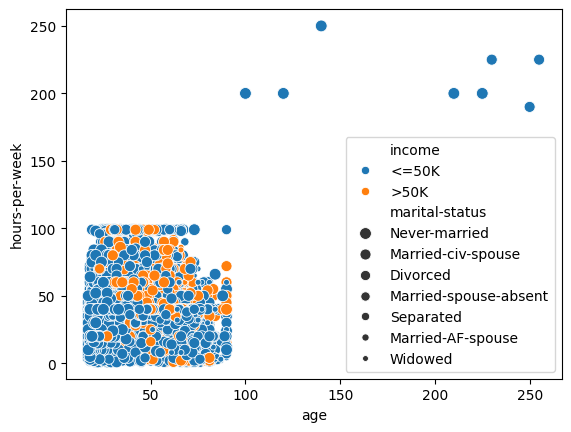

In [160]:
sns.scatterplot(data=df,x="age",y="hours-per-week",hue='income',size='marital-status')
plt.show()

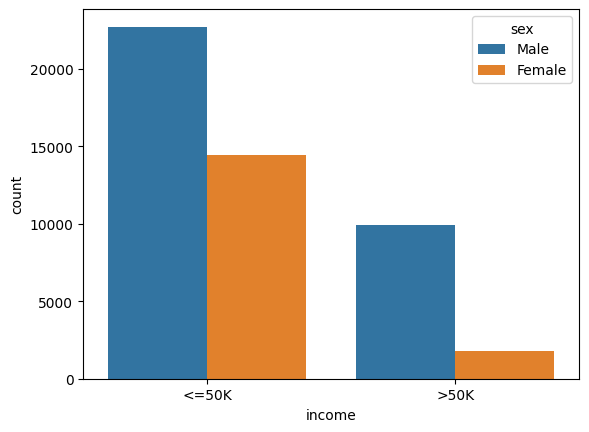

In [161]:
sns.countplot(data=df,x='income',hue='sex')
plt.show()

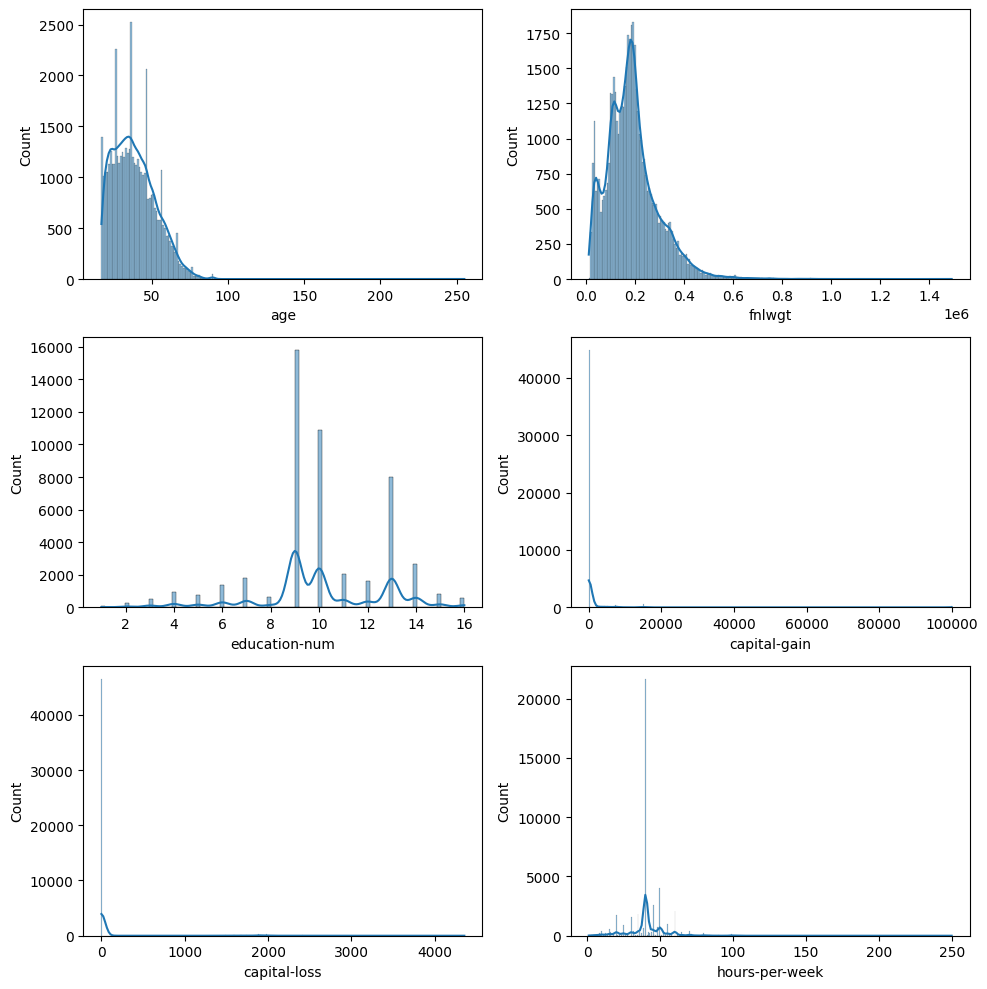

In [108]:
plt.figure(figsize=(10,10))
for i,col in enumerate(df.select_dtypes(include='number').columns,1):
  plt.subplot(3,2,i)
  sns.histplot(df[col],kde=True)
plt.tight_layout()
plt.show()

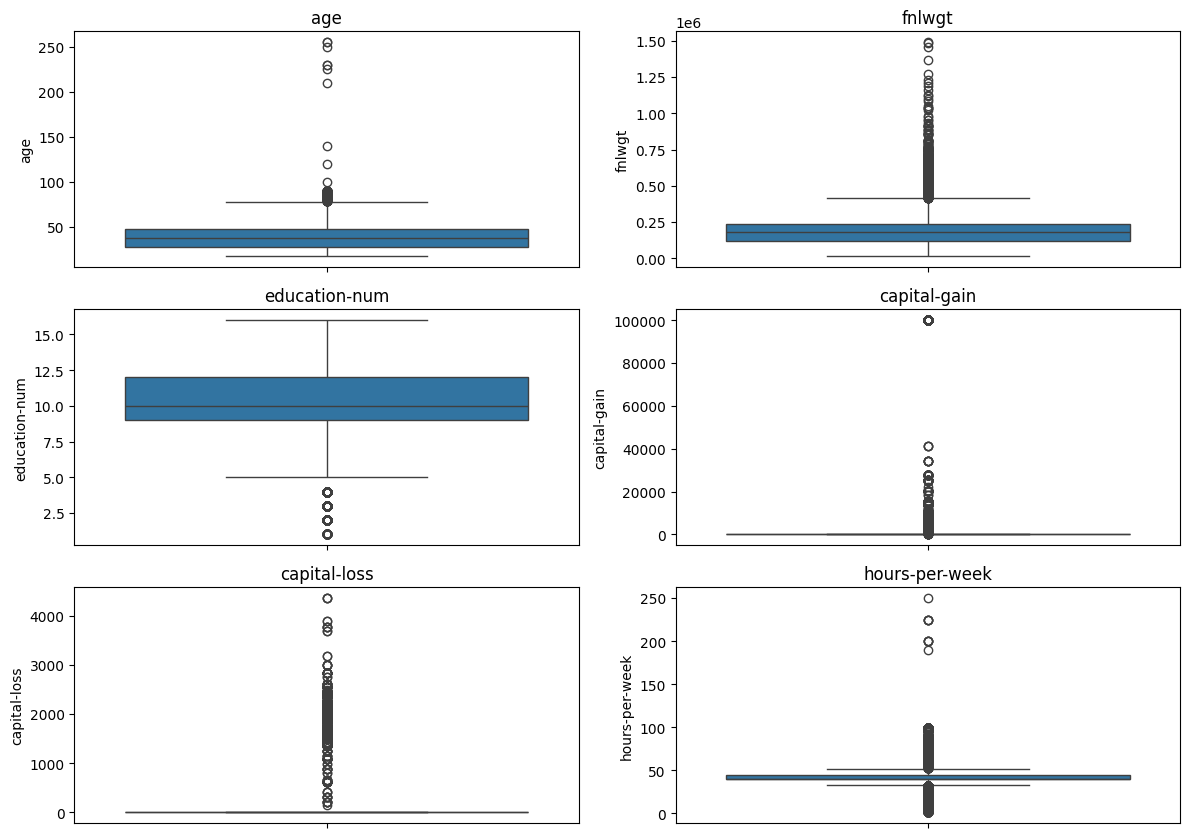

In [109]:
plt.figure(figsize=(12,14))
for i,col in enumerate(df.select_dtypes(include='number').columns,1):
  plt.subplot(5,2,i)
  sns.boxplot(df[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [136]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    # print(f'{col}: {len(outliers)} outliers')

    outlier_count = ((df[col] < lower_limit) |
                     (df[col] > upper_limit)).sum()

    outlier_percentage = (outlier_count / len(df)) * 100

    print(f'{col}: {outlier_count} outliers ({outlier_percentage:.2f}%)')

age: 210 outliers (0.43%)
fnlwgt: 1453 outliers (2.98%)
education-num: 1790 outliers (3.67%)
capital-gain: 4035 outliers (8.27%)
capital-loss: 2282 outliers (4.67%)
hours-per-week: 12832 outliers (26.29%)


In [137]:
df['hours-per-week'].describe()

,hours-per-week
count,46371.000000
mean,40.451360
std,12.647173
min,1.000000
25%,40.000000
50%,40.000000
75%,45.000000
max,250.000000


In [138]:
df['hours-per-week'].value_counts().sort_index()

,count
hours-per-week,
1.0,27
2.0,50
3.0,54
4.0,77
5.0,91
...,...
99.0,128
190.0,1
200.0,4


In [139]:
df[df['hours-per-week'] >= 80]['hours-per-week'].value_counts().sort_index()

,count
hours-per-week,
80.0,195
81.0,2
82.0,1
84.0,69
85.0,16
86.0,4
87.0,1
88.0,3
89.0,3


In [110]:
df.duplicated().sum()

np.int64(29)

In [111]:
df.drop_duplicates(inplace=True)

In [112]:
df.duplicated().sum()

np.int64(0)

In [140]:
numeric_cols = df.select_dtypes(include='number').columns

df[numeric_cols].skew().sort_values(ascending=False)

,0
capital-gain,11.891093
capital-loss,4.568263
fnlwgt,1.439562
age,0.975080
hours-per-week,0.787067
education-num,-0.315155


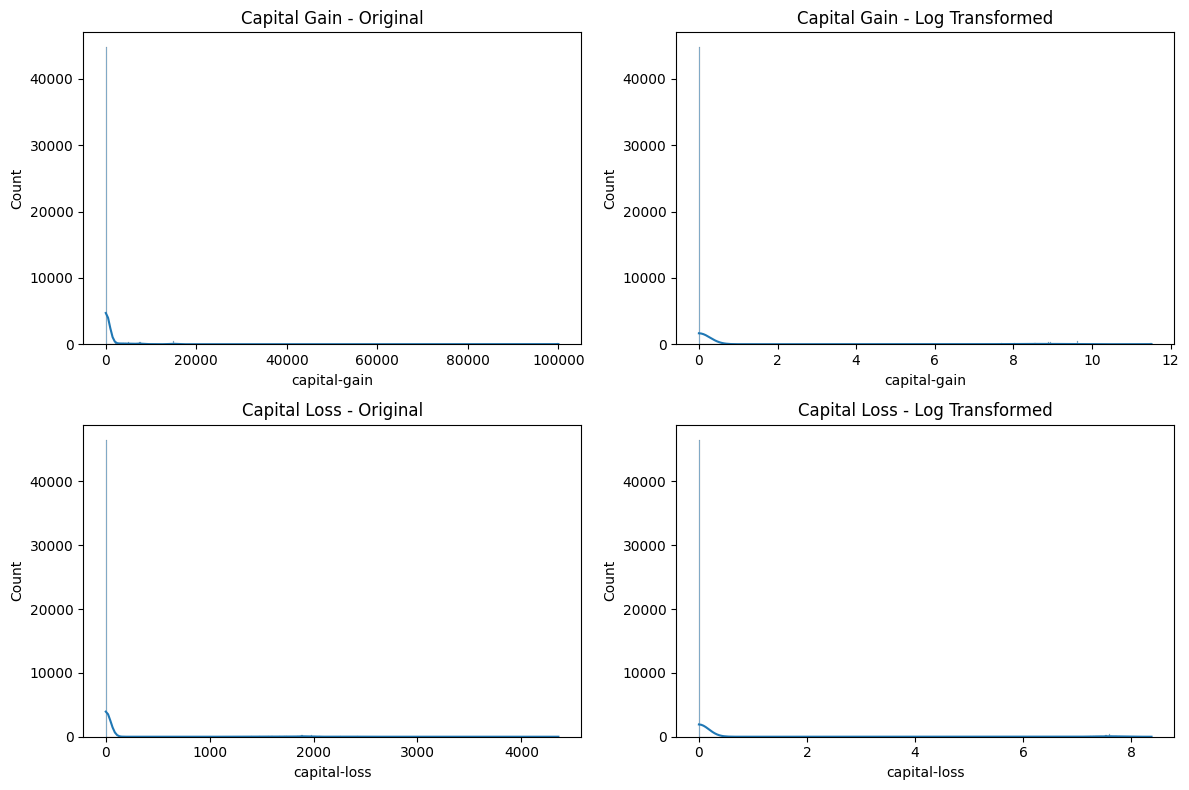

In [141]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['capital-gain'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Capital Gain - Original')

sns.histplot(np.log1p(df['capital-gain']), kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Capital Gain - Log Transformed')

sns.histplot(df['capital-loss'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Capital Loss - Original')

sns.histplot(np.log1p(df['capital-loss']), kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Capital Loss - Log Transformed')

plt.tight_layout()
plt.show()

In [142]:
print("Original Skewness:")
print(df[['capital-gain', 'capital-loss']].skew())

print("\nLog Transformed Skewness:")
print(np.log1p(df[['capital-gain', 'capital-loss']]).skew())

Original Skewness:
capital-gain    11.891093
capital-loss     4.568263
dtype: float64

Log Transformed Skewness:
capital-gain    3.112437
capital-loss    4.301482
dtype: float64


#Splitting the data

In [113]:
X=df.drop('income',axis=1)
y=df['income']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [114]:
X_train

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
33441,NaN,NaN,207668,Bachelors,13,Never-married,NaN,Own-child,White,Male,0,0,40.0,United-States
39981,44.0,Private,40024,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,0,40.0,United-States
47829,37.0,Private,53232,Prof-school,15,Never-married,Prof-specialty,Not-in-family,Asian-Pac-Islander,Female,0,0,55.0,United-States
46480,23.0,State-gov,71996,Bachelors,13,Never-married,Adm-clerical,Own-child,Asian-Pac-Islander,Female,0,0,52.0,United-States
30890,45.0,Private,34127,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50.0,United-States
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5287,33.0,NaN,118941,Bachelors,13,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,32.0,United-States
30878,39.0,Private,230356,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Female,0,0,40.0,United-States
7684,32.0,Private,209103,Some-college,10,Married-civ-spouse,Exec-managerial,Husband,White,Male,3464,0,40.0,United-States
45262,47.0,Private,131160,Bachelors,13,Divorced,Other-service,Not-in-family,White,Female,99999,0,40.0,United-States


In [115]:
num_cols=X_train.select_dtypes(include='number').columns
cat_cols=X_train.select_dtypes(include='object').columns

In [116]:
num_cols

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [117]:
cat_cols

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

#Handling Numerical columns

In [118]:
#Handling missing values
num_imputer=SimpleImputer(strategy='median')
X_train_num=num_imputer.fit_transform(X_train[num_cols])
X_test_num=num_imputer.transform(X_test[num_cols])

In [119]:
#Scaling the num values
scaler = StandardScaler()
X_train_num_scale=scaler.fit_transform(X_train_num)
X_test_num_scale=scaler.transform(X_test_num)

In [120]:
X_train_num_scale=pd.DataFrame(
    X_train_num_scale,
    columns=num_cols,
    index=X_train.index
)

X_test_num_scale=pd.DataFrame(
    X_test_num_scale,
    columns=num_cols,
    index=X_test.index
)

#Handling Categorical columns

In [121]:
for col in cat_cols:
  print(f"{col} : {df[col].unique()}\n")


workclass : ['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' nan 'Local-gov'
 'Self-emp-inc' 'Without-pay' 'Never-worked']

education : ['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']

marital-status : ['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']

occupation : ['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' nan
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']

relationship : ['Not-in-family' 'Husband' 'Wife' 'Own-child' 'Unmarried' 'Other-relative']

race : ['White' 'Black' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Other']

sex : ['Male' 'Female']

native-country : [nan 'United-States' 'Cuba' 'Jamaica' 'India' 'Mexico' 'South'
 'Puerto-Rico' 'Hondur

In [122]:
cat_imputer=SimpleImputer(strategy='most_frequent')
X_train_cat=cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat=cat_imputer.transform(X_test[cat_cols])


In [123]:
# for col in cat_cols:
#   print(f"{col} : {df[col].unique()}\n")


In [124]:
one_hot_encoder=OneHotEncoder(sparse_output=False,handle_unknown='ignore')
X_train_cat=one_hot_encoder.fit_transform(X_train_cat)
X_test_cat=one_hot_encoder.transform(X_test_cat)

In [125]:
column_names=one_hot_encoder.get_feature_names_out(cat_cols)
X_train_cat=pd.DataFrame(
    X_train_cat,
    columns=column_names,
    index=X_train.index
)
X_test_cat=pd.DataFrame(
    X_test_cat,
    columns=column_names,
    index=X_test.index
)

In [126]:
X_train_cat
X_test_cat

,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_10th,education_11th,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
20885,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
29249,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
28922,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2213,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
27117,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
253,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
286,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
21881,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
11388,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [127]:
X_train_final=pd.concat([X_train_num_scale,X_train_cat],axis=1)
X_test_final=pd.concat([X_test_num_scale,X_test_cat],axis=1)

In [128]:
label_encoder=LabelEncoder()
y_train=pd.Series(label_encoder.fit_transform(y_train))
y_test=pd.Series(label_encoder.transform(y_test))


In [146]:
label_encoder.classes_

array(['<=50K', '>50K'], dtype=object)

In [129]:
smote = SMOTE(random_state=42)
X_train_balanced,y_train_balanced=smote.fit_resample(X=X_train_final,y=y_train)

In [130]:
y_train.value_counts()

,count
0,29701
1,9349


In [131]:
y_train_balanced.value_counts()

,count
0,29701
1,29701


In [132]:
# corr = X_train_balanced.corr()
# plt.figure(figsize=(18,12))
# sns.heatmap(corr,annot=True,fmt=".2f",cmap='coolwarm',linewidths=.5)
# plt.show()

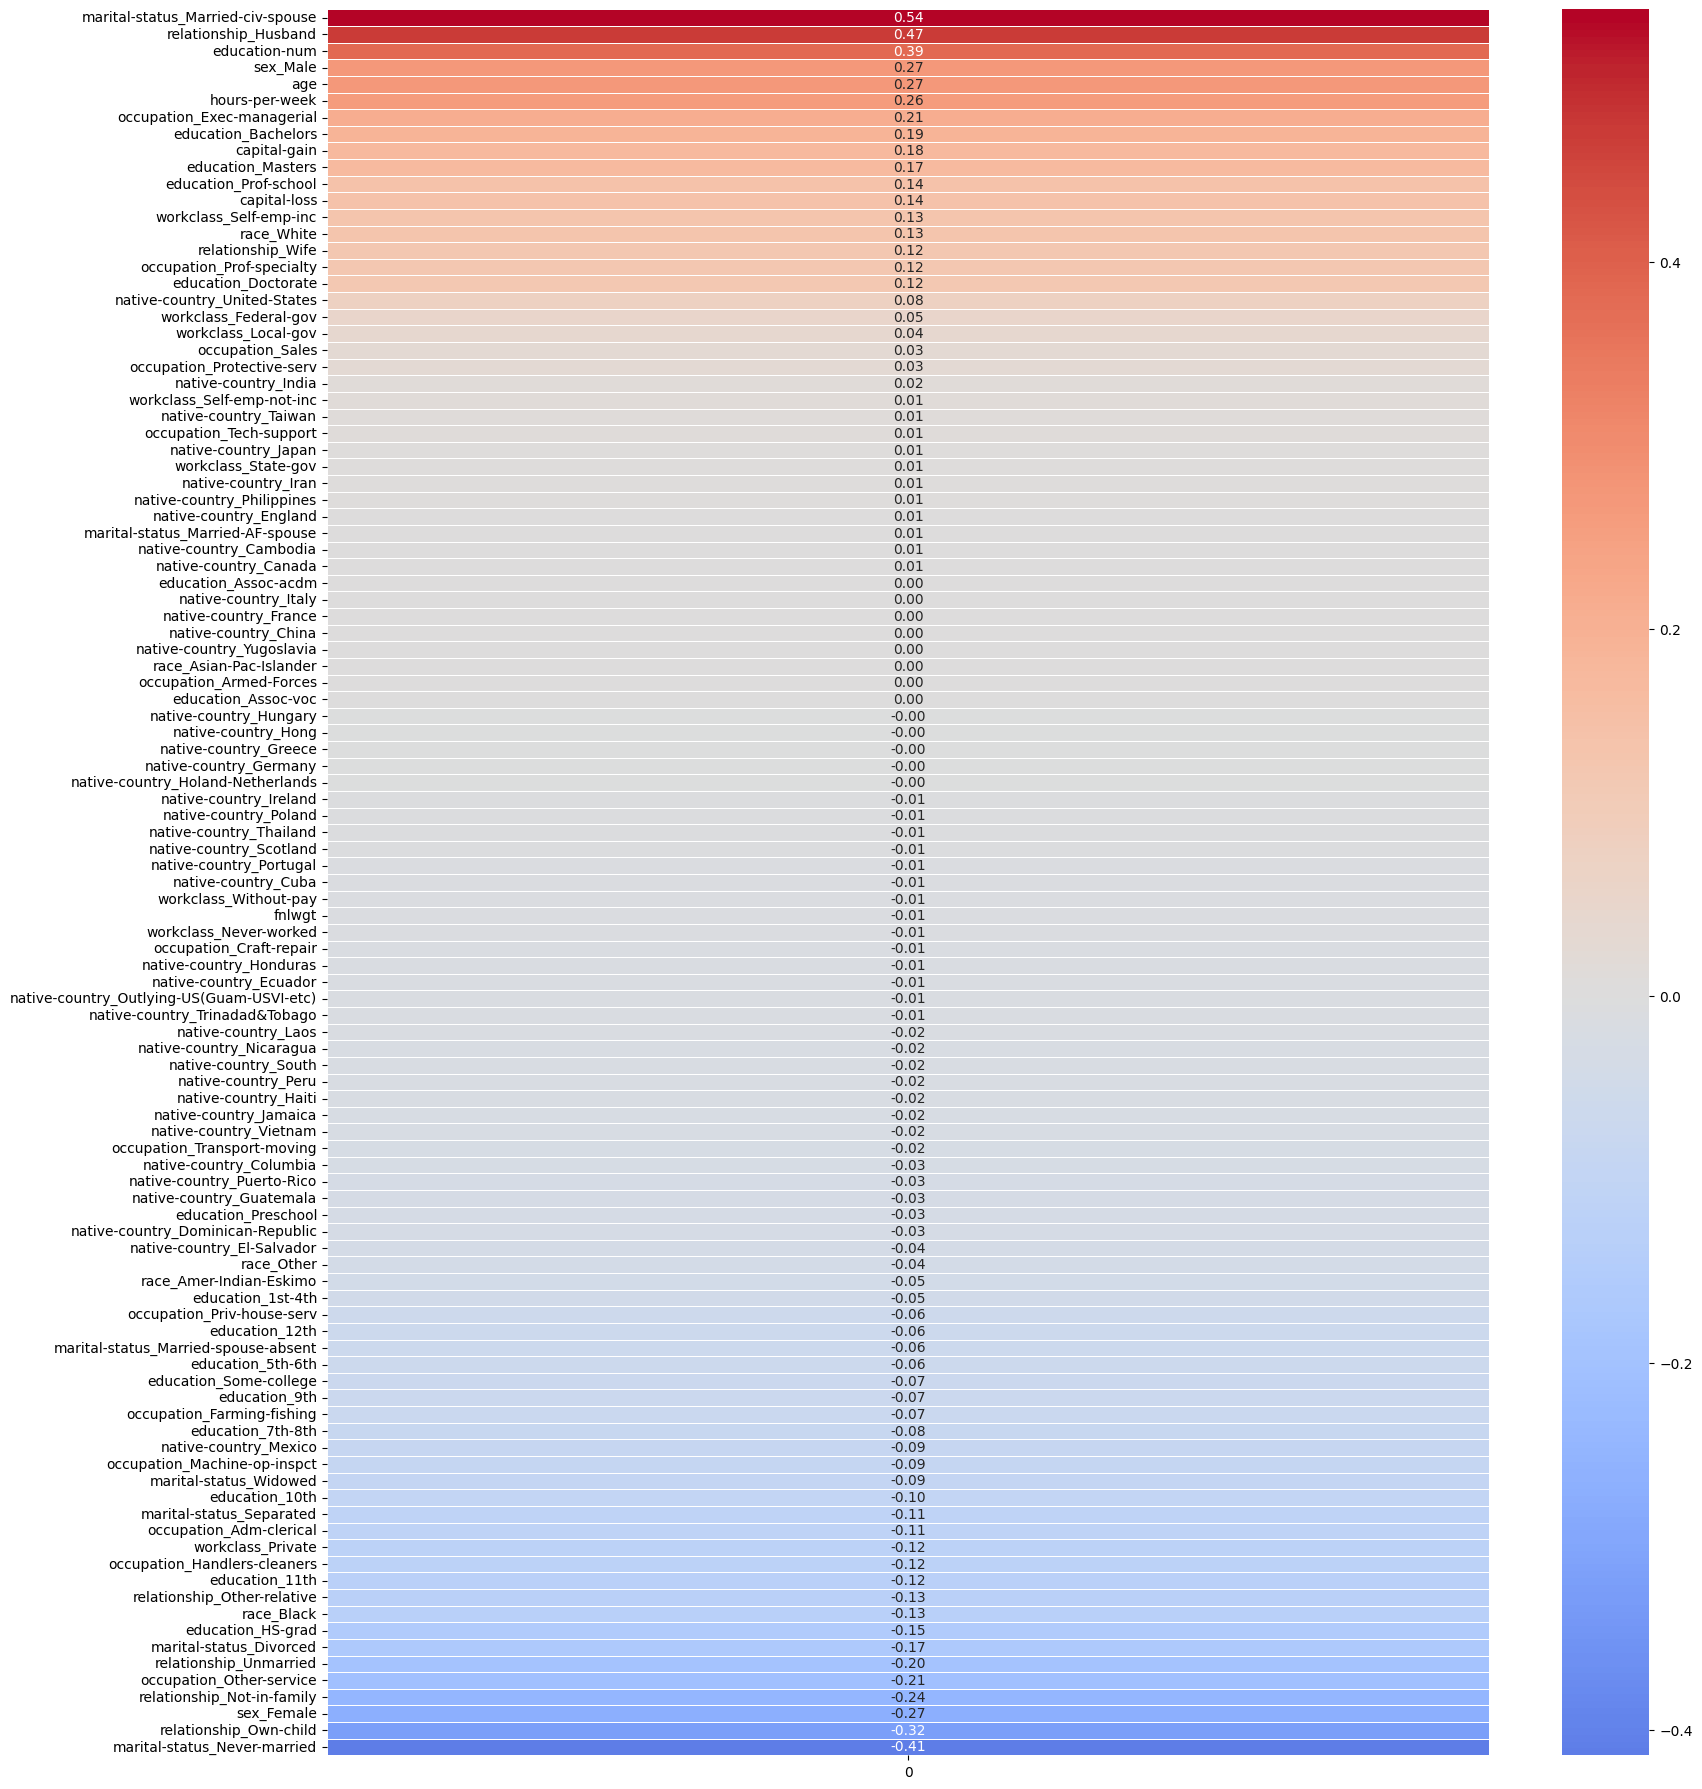

In [143]:
corr_target=X_train_balanced.corrwith(y_train_balanced).sort_values(ascending=False).to_frame()
plt.figure(figsize=(18,18))
sns.heatmap(corr_target,annot=True,fmt=".2f",cmap='coolwarm',linewidths=.5,center=0,yticklabels=True)
plt.tight_layout()
plt.show()

In [145]:
corr_target

,0
marital-status_Married-civ-spouse,0.537764
relationship_Husband,0.473420
education-num,0.385334
sex_Male,0.269340
age,0.268950
...,...
occupation_Other-service,-0.208990
relationship_Not-in-family,-0.244504
sex_Female,-0.269340
relationship_Own-child,-0.317860


In [144]:
selected_features=['education_num','relationship_Husband','Marital_status_Married-civ-spouse']

In [147]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.01)

X_train_selected = selector.fit_transform(X_train_balanced)

In [148]:
# Get the names of all features
feature_names = X_train_balanced.columns

# Features retained
selected_features = feature_names[selector.get_support()]

# Features removed
removed_features = feature_names[~selector.get_support()]

print("Selected Features:", len(selected_features))
print(selected_features.tolist())

print("\nRemoved Features:", len(removed_features))
print(removed_features.tolist())

Selected Features: 54
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass_Federal-gov', 'workclass_Local-gov', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'education_10th', 'education_11th', 'education_7th-8th', 'education_9th', 'education_Assoc-acdm', 'education_Assoc-voc', 'education_Bachelors', 'education_Doctorate', 'education_HS-grad', 'education_Masters', 'education_Prof-school', 'education_Some-college', 'marital-status_Divorced', 'marital-status_Married-civ-spouse', 'marital-status_Never-married', 'marital-status_Separated', 'marital-status_Widowed', 'occupation_Adm-clerical', 'occupation_Craft-repair', 'occupation_Exec-managerial', 'occupation_Farming-fishing', 'occupation_Handlers-cleaners', 'occupation_Machine-op-inspct', 'occupation_Other-service', 'occupation_Prof-specialty', 'occupation_Protective-serv', 'occupation_Sales', 'occupation_Tech-support', 'occupation_Transport-m

In [149]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train_balanced,
    y_train_balanced,
    random_state=42
)

mi_scores = pd.Series(
    mi_scores,
    index=X_train_balanced.columns
).sort_values(ascending=False)

mi_scores

,0
age,0.336951
hours-per-week,0.183645
marital-status_Married-civ-spouse,0.169285
relationship_Husband,0.130102
education-num,0.102808
...,...
native-country_Peru,0.000000
native-country_Puerto-Rico,0.000000
native-country_Trinadad&Tobago,0.000000
native-country_Vietnam,0.000000


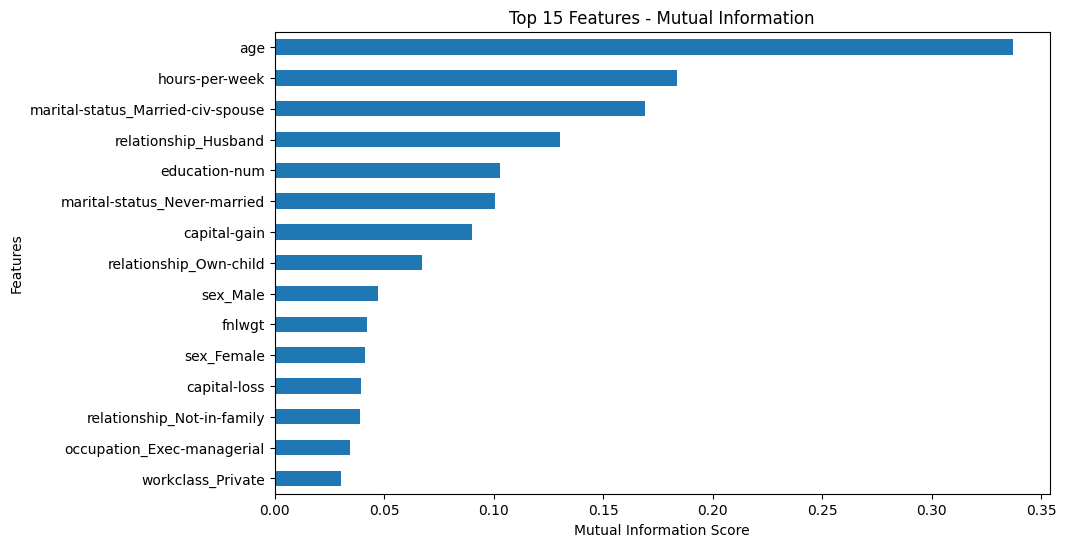

In [150]:
plt.figure(figsize=(10, 6))

mi_scores.head(15).sort_values().plot(kind='barh')

plt.title('Top 15 Features - Mutual Information')
plt.xlabel('Mutual Information Score')
plt.ylabel('Features')
plt.show()